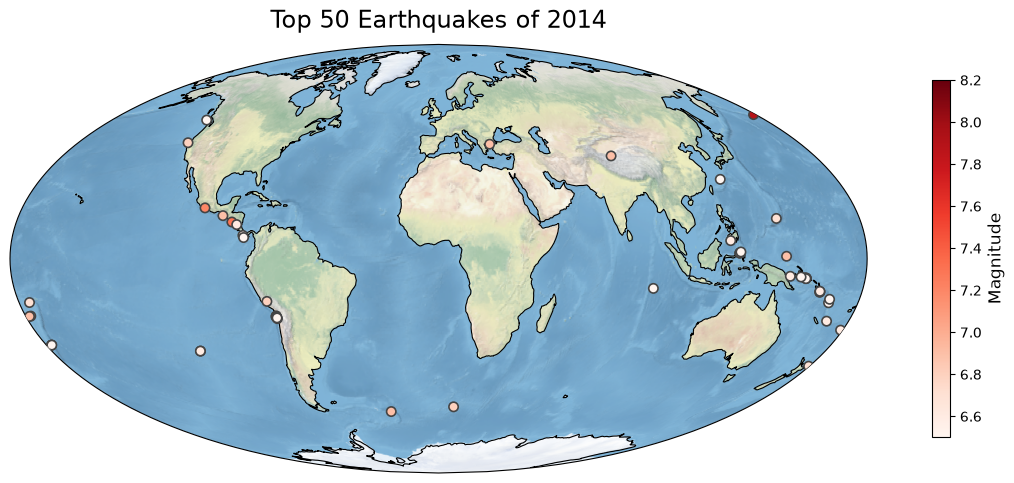

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs 
%matplotlib inline

df = pd.read_csv("usgs_earthquakes.csv")

df.head()
df.columns


# 清洗和选取数据
df['time'] = pd.to_datetime(df['time'])

df_2014 = df[(df['time'] >= '2014-01-01') &(df['time'] < '2015-01-01')]

df_2014 = df_2014.dropna(subset=['latitude', 'longitude', 'mag'])


df_sorted = df_2014.sort_values(by='mag',ascending=False)

top50 = df_sorted.head(50)

# 画图
fig = plt.figure(figsize=(14, 8))

ax = plt.axes(projection=ccrs.Mollweide())

ax.stock_img()
ax.coastlines(color='black',linewidth=0.8)
ax.set_global()

sc = ax.scatter(
    top50['longitude'],
    top50['latitude'],
    c=top50['mag'],
    s=45,
    cmap='Reds',
    vmin=6.5,
    vmax=8.2,
    edgecolors='#444444',
    linewidths=1.2,
    transform=ccrs.PlateCarree(),
    zorder=5
)

cbar = plt.colorbar(
    sc,
    ax=ax,
    orientation='vertical',
    shrink=0.58,
    pad=0.06
)

cbar.set_label('Magnitude', fontsize=12)

cbar.set_ticks(np.arange(6.6, 8.21, 0.2))

plt.title(
    'Top 50 Earthquakes of 2014',
    fontsize=17,
    pad=12
)

plt.show()

In [6]:
import numpy as np
import pandas as pd
import xarray as xr

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

import cartopy.crs as ccrs
import cartopy.feature as cfeature

from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from matplotlib.lines import Line2D

%matplotlib inline

#检查数据
ds = xr.open_dataset("CESM2_200001-201412.nc")

print(ds)
print(ds.data_vars)


# 清洗数据
tas = ds.tas
tas = tas.where(tas < 1e19)
tas_map = tas.isel(time=-1)

print(tas_map)
print(ds.time.values[-1])

vmin = float(tas_map.min())
vmax = float(tas_map.max())
levels = np.linspace(vmin, vmax, 21)

D:\anacanda\Lib\site-packages\xarray\conventions.py:205: SerializationWarning: variable 'tas' has multiple fill values {np.float32(1e+20), np.float64(1e+20)} defined, decoding all values to NaN.
  var = coder.decode(var, name=name)


<xarray.Dataset> Size: 40MB
Dimensions:    (time: 180, lat: 192, lon: 288, nbnd: 2)
Coordinates:
  * time       (time) object 1kB 2000-01-15 12:00:00 ... 2014-12-15 12:00:00
  * lat        (lat) float64 2kB -90.0 -89.06 -88.12 -87.17 ... 88.12 89.06 90.0
  * lon        (lon) float64 2kB 0.0 1.25 2.5 3.75 ... 355.0 356.2 357.5 358.8
Dimensions without coordinates: nbnd
Data variables:
    tas        (time, lat, lon) float32 40MB ...
    time_bnds  (time, nbnd) object 3kB ...
    lat_bnds   (lat, nbnd) float64 3kB ...
    lon_bnds   (lon, nbnd) float64 5kB ...
Attributes: (12/45)
    Conventions:            CF-1.7 CMIP-6.2
    activity_id:            CMIP
    branch_method:          standard
    branch_time_in_child:   674885.0
    branch_time_in_parent:  219000.0
    case_id:                972
    ...                     ...
    sub_experiment_id:      none
    table_id:               Amon
    tracking_id:            hdl:21.14100/a7278f6d-6a1b-4050-8f06-a8033604736a
    variable_id:   

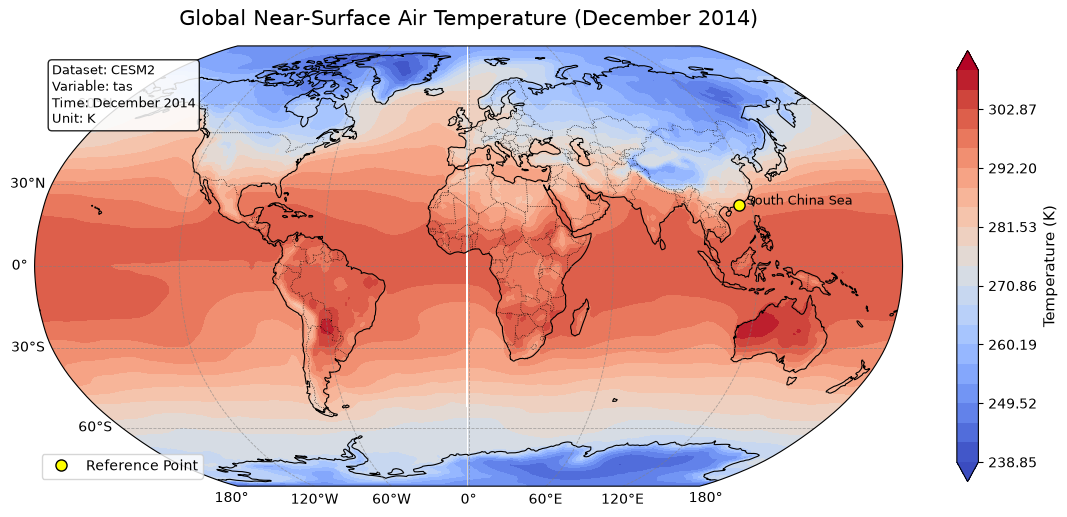

In [8]:
# 2.1 绘制全球气温分布图
fig = plt.figure(figsize=(14, 8))
ax = plt.axes(projection=ccrs.Robinson())

ax.set_global()
im = ax.contourf(
    tas_map.lon,
    tas_map.lat,
    tas_map,
    levels=levels,
    cmap='coolwarm',
    extend='both',
    transform=ccrs.PlateCarree()
)

#feature
ax.add_feature(
    cfeature.LAND,
    facecolor='lightgray',
    zorder=0
)

ax.coastlines(
    linewidth=0.8,
    color='black'
)

ax.add_feature(
    cfeature.BORDERS,
    linestyle=':',
    linewidth=0.5
)


# 网格线
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    linewidth=0.6,
    color='gray',
    alpha=0.6,
    linestyle='--',
    x_inline=False,
    y_inline=False
)

gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))

gl.ylocator = mticker.FixedLocator(np.arange(-60, 61, 30))

gl.xformatter = LongitudeFormatter()
gl.yformatter = LatitudeFormatter()

gl.top_labels = False
gl.right_labels = False


# x，y标签

ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

#题目
plt.title(
    'Global Near-Surface Air Temperature (December 2014)',
    fontsize=15,
    pad=15
)

#colorbar
cbar = plt.colorbar(
    im,
    ax=ax,
    orientation='vertical',
    shrink=0.7,
    pad=0.05
)

cbar.set_label('Temperature (K)', fontsize=11)


#注释
ax.scatter(
    114.55,
    22.5,
    color='yellow',
    edgecolors='black',
    s=65,
    transform=ccrs.PlateCarree(),
    zorder=5
)

ax.text(
    114.55,
    22.5,
    '  South China Sea',
    fontsize=9,
    color='black',
    transform=ccrs.PlateCarree()
)


#图例
legend_element = [
    Line2D(
        [0], [0],
        marker='o',
        color='w',
        label='Reference Point',
        markerfacecolor='yellow',
        markeredgecolor='black',
        markersize=8
    )
]

ax.legend(
    handles=legend_element,
    loc='lower left'
)


# 文本框
text = (
    'Dataset: CESM2\n'
    'Variable: tas\n'
    'Time: December 2014\n'
    'Unit: K'
)

ax.text(
    0.02,
    0.96,
    text,
    transform=ax.transAxes,
    fontsize=9,
    verticalalignment='top',
    bbox=dict(
        boxstyle='round',
        facecolor='white',
        alpha=0.85
    )
)

plt.show()

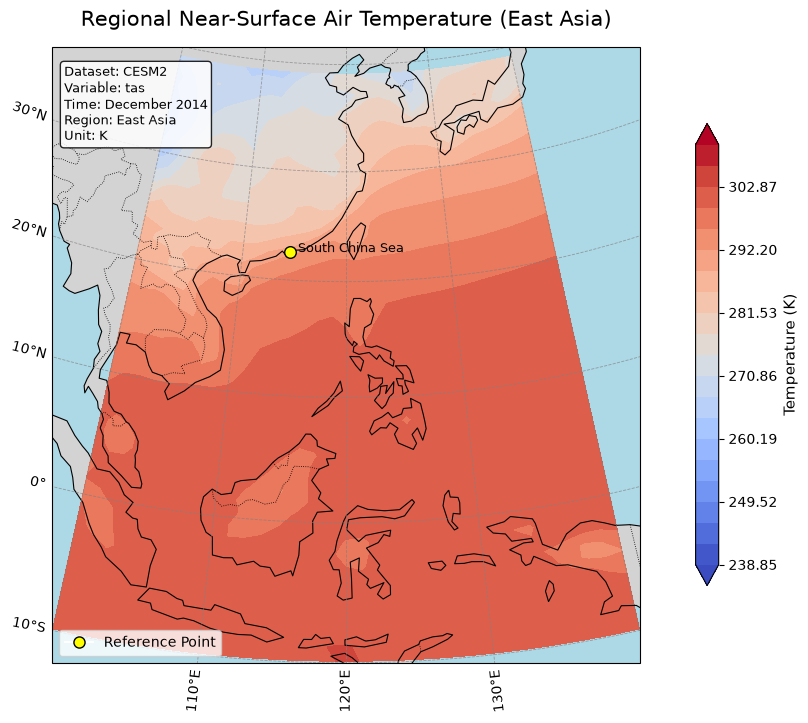

In [10]:
# 2.2绘制区域气温分布图

#选择区域
tas_region = tas_map.sel(
    lon=slice(100, 140),
    lat=slice(-10, 40)
)
tas_region

fig = plt.figure(figsize=(12, 8))

ax = plt.axes(
    projection=ccrs.LambertConformal(
        central_longitude=120,
        central_latitude=15
    )
)

ax.set_extent(
    [100, 140, -10, 40],
    crs=ccrs.PlateCarree()
)


# 绘制区域气温
im = ax.contourf(
    tas_region.lon,
    tas_region.lat,
    tas_region,
    levels=levels,
    cmap='coolwarm',
    extend='both',
    transform=ccrs.PlateCarree()
)


# features
ax.add_feature(
    cfeature.LAND,
    facecolor='lightgray',
    zorder=0
)

ax.add_feature(
    cfeature.OCEAN,
    facecolor='lightblue',
    zorder=0
)

ax.coastlines(
    linewidth=0.8,
    color='black'
)

ax.add_feature(
    cfeature.BORDERS,
    linestyle=':',
    linewidth=0.6
)


#gridlines
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    linewidth=0.6,
    color='gray',
    alpha=0.7,
    linestyle='--',
    x_inline=False,
    y_inline=False
)

gl.xlocator = mticker.FixedLocator(
    np.arange(100, 141, 10)
)

gl.ylocator = mticker.FixedLocator(
    np.arange(-10, 41, 10)
)

gl.xformatter = LongitudeFormatter()
gl.yformatter = LatitudeFormatter()

gl.top_labels = False
gl.right_labels = False


# x and y labels
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')


#title
plt.title(
    'Regional Near-Surface Air Temperature (East Asia)',
    fontsize=15,
    pad=15
)


#colorbar
cbar = plt.colorbar(
    im,
    ax=ax,
    orientation='vertical',
    shrink=0.75,
    pad=0.06
)

cbar.set_label('Temperature (K)', fontsize=11)


#annotation
ax.scatter(
    114.55,
    22.5,
    color='yellow',
    edgecolors='black',
    s=70,
    transform=ccrs.PlateCarree(),
    zorder=5
)

ax.text(
    114.55,
    22.5,
    '  South China Sea',
    fontsize=9,
    transform=ccrs.PlateCarree()
)


#legend
legend_element = [
    Line2D(
        [0], [0],
        marker='o',
        color='w',
        label='Reference Point',
        markerfacecolor='yellow',
        markeredgecolor='black',
        markersize=8
    )
]

ax.legend(
    handles=legend_element,
    loc='lower left'
)


#text box
text = (
    'Dataset: CESM2\n'
    'Variable: tas\n'
    'Time: December 2014\n'
    'Region: East Asia\n'
    'Unit: K'
)

ax.text(
    0.02,
    0.97,
    text,
    transform=ax.transAxes,
    fontsize=9,
    verticalalignment='top',
    bbox=dict(
        boxstyle='round',
        facecolor='white',
        alpha=0.85
    )
)

plt.show()